# Rust rewrite: results

The pipeline in [`../src`](../src) is the same millisecond loop as the Python project ([neurostream-python](https://github.com/bsrihan/neurostream-python)): re-reference, forward Butterworth 250-5000 Hz, 4 ms reverse filter, threshold crossings and spike-band power. This notebook checks that it gives the same answer as the Python path kept after week 2, and shows where the time goes. The code behind the cells is in [`../scripts/timing.py`](../scripts/timing.py); this notebook only plots.

Every timing is **milliseconds of compute per second of data** on this machine. Under 1000 is real time. Synthetic data is 200 windows (0.2 s) of Gaussian noise with planted spikes, used for electrode counts the public recording does not have; the real recording is the first 10 s of `NSP1_aligned.ns6` (128 electrodes).

Three paths appear in the graphs:

- **original loop**: the Python project's first implementation, as a reference point only;
- **Python kept path**: `OptimizedProcessor` after week 2 (block re-reference, AVX-512 forward filter, reverse filter as one multiply), single thread;
- **Rust**: this crate, one thread, and with four lanes (one per core).


In [1]:
%matplotlib inline
import sys
import time

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, "../scripts")
import neurostream
import paths
import timing
from timing import SAMPLES_PER_MS, SAMPLE_RATE, STAGES, STAGE_LABELS

SECONDS = 10
CHANNELS = (64, 256, 1024, 2048)
COLORS = {"original loop": "0.6", "Python kept path": "tab:blue", "Rust, 1 thread": "tab:orange", "Rust, 4 lanes": "tab:red"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

RECORDING, PARAMS = paths.require_data("lrr")
paths.add_python_project()
print("neurostream", neurostream.__version__, "-", neurostream.build_target())
print(timing.cpu_label())


neurostream 0.1.0 - x86_64 with AVX-512 (eight f64 per instruction)
Intel(R) Xeon(R) Processor, 4 cores, AVX-512


## 1. Same answer

Rust and the Python kept path on the same 10 s of the recording, with the LRR parameter file the earlier notebooks use. Left: one electrode for 30 ms, both waveforms and both sets of spikes. Right: every filtered sample's difference, in units of the recording (0.25 µV).

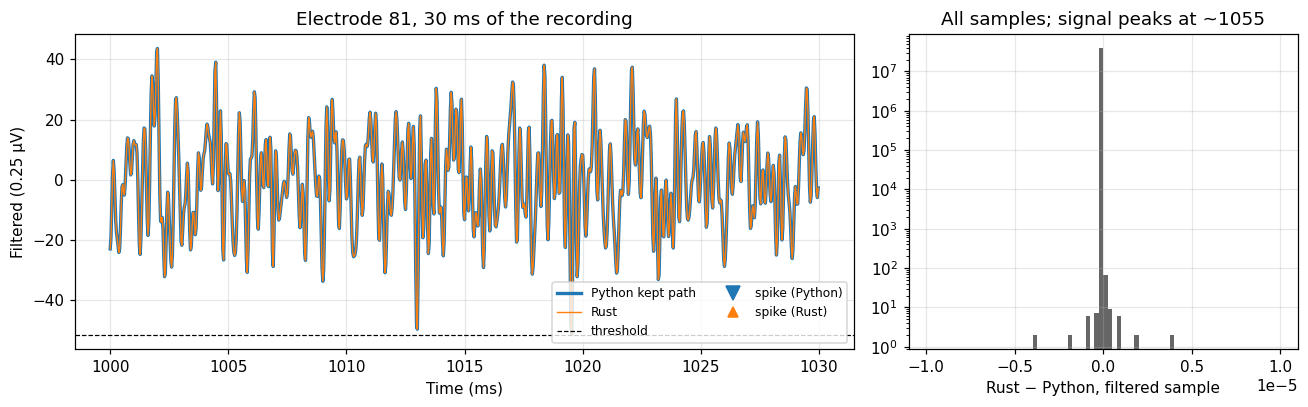

spikes: Python 26611, Rust 26611, bins that differ 0
filtered: max |difference| 3.8e-06; spike-band power max |difference| 1.1e-05 dB


In [2]:
reref, thresholds, groups, P = timing.load_params(PARAMS)
raw, rate = neurostream.read_ns6(str(RECORDING), max_samples=SECONDS * SAMPLE_RATE)   # (n_samples, n_channels) int16

t0 = time.perf_counter(); rs = neurostream.Processor(reref, thresholds, groups, threads=1).process_recording(raw); t_rust = time.perf_counter() - t0
py_proc = timing.kept_path_processor(raw.shape[1], reref, thresholds, groups)
t0 = time.perf_counter(); py = py_proc.process_recording(raw.T); t_py = time.perf_counter() - t0
AGREE = timing.agreement(rs, py)

ch, t0_ms, span_ms = 81, 1000, 30
s = slice(t0_ms * SAMPLES_PER_MS, (t0_ms + span_ms) * SAMPLES_PER_MS)
tt = np.arange(s.start, s.stop) / SAMPLES_PER_MS
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [2, 1]})
ax = axes[0]
ax.plot(tt, py.filtered[ch, s], color=COLORS["Python kept path"], lw=2.2, label="Python kept path")
ax.plot(tt, rs["filtered"][ch, s], color=COLORS["Rust, 1 thread"], lw=0.9, label="Rust")
ax.axhline(thresholds[ch], color="k", ls="--", lw=0.8, label="threshold")
for spikes, marker, size, name in ((py.spikes, "v", 9, "Python"), (rs["spikes"], "^", 6, "Rust")):
    w = np.flatnonzero(spikes[ch, t0_ms:t0_ms + span_ms]) + t0_ms
    ax.plot(w + 0.5, np.full(w.size, thresholds[ch] * 1.6), marker, color=COLORS["Python kept path" if name == "Python" else "Rust, 1 thread"], ms=size, label=f"spike ({name})")
ax.set_xlabel("Time (ms)"); ax.set_ylabel("Filtered (0.25 µV)"); ax.set_title(f"Electrode {ch}, {span_ms} ms of the recording"); ax.legend(loc="lower right", fontsize=8, ncol=2)
ax = axes[1]
ax.hist(AGREE["filt_diff"], bins=np.linspace(-1e-5, 1e-5, 81), color="0.4"); ax.set_yscale("log")
ax.set_xlabel("Rust − Python, filtered sample"); ax.set_title(f"All samples; signal peaks at ~{AGREE['filt_scale']:.0f}")
fig.tight_layout(); plt.show()

print(f"spikes: Python {AGREE['spikes_py']}, Rust {AGREE['spikes_rust']}, bins that differ {AGREE['spike_mismatch']}")
print(f"filtered: max |difference| {AGREE['filt_max']:.1e}; spike-band power max |difference| {AGREE['sbp_max']:.1e} dB")


## 2. Where the time goes

Steady state: the processor is already built, the output arrays already exist, and only the per-millisecond work is timed. Rust is timed by `neurostream-bench`; the two Python paths are timed in this kernel the same way the Python project's `optimization_results.ipynb` does. 200 windows, median of 3 runs. The stage split is a second, instrumented run with the clock stopped between stages, so its sum is a little above the plain total.

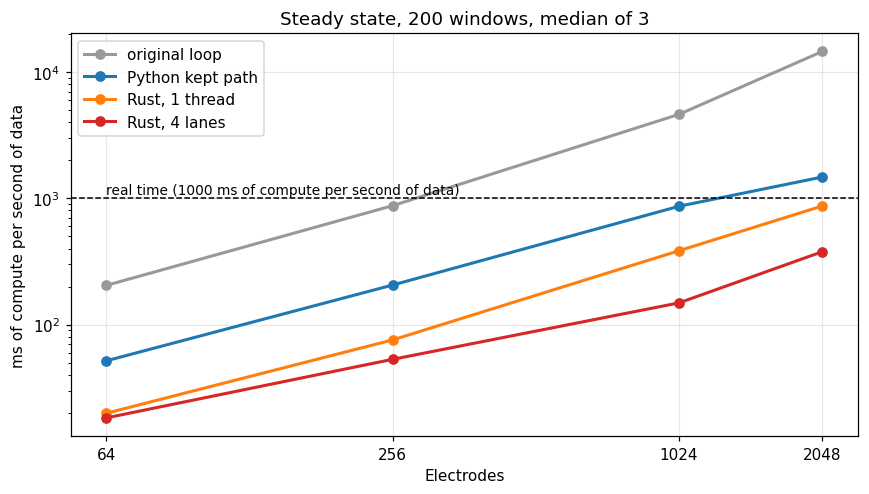

 channels     original loop  Python kept path    Rust, 1 thread     Rust, 4 lanes
       64               204                52                20                18
      256               874               206                76                53
     1024              4620               864               384               148
     2048             14528              1473               868               377


In [3]:
STEADY, SPLIT = timing.steady_state_table(CHANNELS, n_ms=200, repeats=3)

fig, ax = plt.subplots(figsize=(8, 4.6))
for name, series in STEADY.items():
    ax.plot(CHANNELS, [series[n] for n in CHANNELS], "o-", color=COLORS[name], label=name, lw=2)
ax.axhline(1000, color="k", ls="--", lw=1); ax.text(CHANNELS[0], 1080, "real time (1000 ms of compute per second of data)", fontsize=9)
ax.set_xscale("log", base=2); ax.set_yscale("log"); ax.set_xticks(CHANNELS); ax.set_xticklabels(CHANNELS)
ax.set_xlabel("Electrodes"); ax.set_ylabel("ms of compute per second of data"); ax.set_title("Steady state, 200 windows, median of 3")
ax.legend(); fig.tight_layout(); plt.show()

print(f"{'channels':>9}" + "".join(f"{k:>18}" for k in STEADY))
for n in CHANNELS:
    print(f"{n:9d}" + "".join(f"{STEADY[k][n]:18.0f}" for k in STEADY))


### Stage split

The same five stages in both projects, timed with the clock stopped between them. "write" is copying the millisecond's results into the recording-sized output arrays.

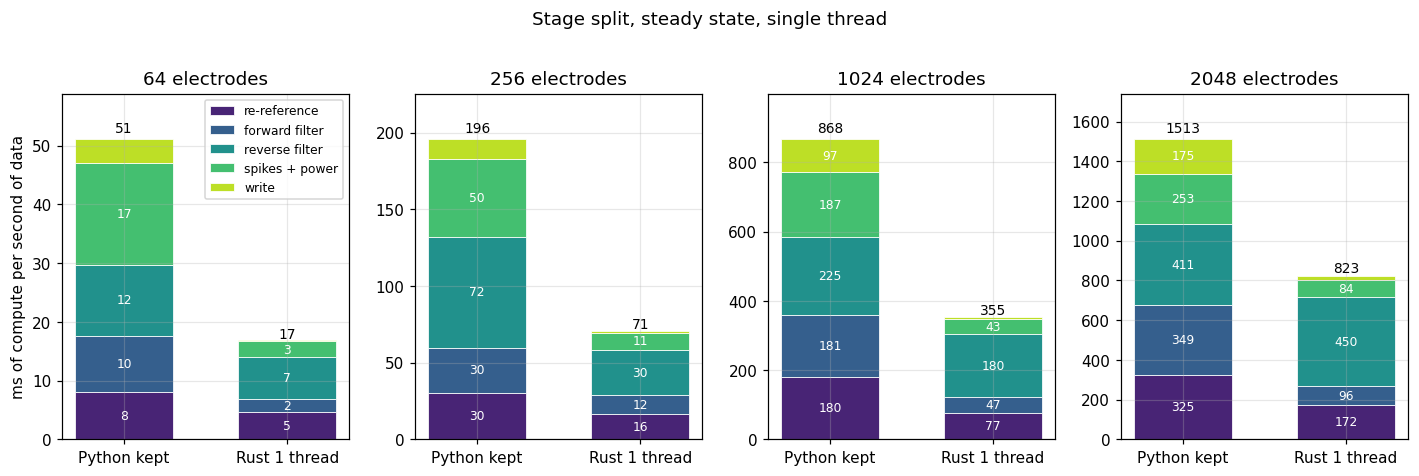

In [4]:
stage_colors = plt.cm.viridis(np.linspace(0.1, 0.9, 5))
fig, axes = plt.subplots(1, len(CHANNELS), figsize=(13, 4.2))
for ax, n in zip(axes, CHANNELS):
    for xi, name in enumerate(("Python kept path", "Rust, 1 thread")):
        bottom = 0.0
        total = sum(SPLIT[(name, n)].values())
        for k, c in zip(STAGES, stage_colors):
            v = SPLIT[(name, n)][k]
            ax.bar(xi, v, 0.6, bottom=bottom, color=c, edgecolor="white", lw=0.5, label=STAGE_LABELS[k] if (n == CHANNELS[0] and xi == 0) else None)
            if v > 0.08 * total:
                ax.text(xi, bottom + v / 2, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white")
            bottom += v
        ax.text(xi, bottom * 1.02, f"{bottom:.0f}", ha="center", fontsize=9)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Python kept", "Rust 1 thread"]); ax.set_title(f"{n} electrodes")
    ax.set_ylim(0, max(sum(SPLIT[(nm, n)].values()) for nm in ("Python kept path", "Rust, 1 thread")) * 1.15)
axes[0].set_ylabel("ms of compute per second of data"); axes[0].legend(fontsize=8, loc="upper right")
fig.suptitle("Stage split, steady state, single thread", y=1.02); fig.tight_layout(); plt.show()


### Lanes

Each lane owns a block of electrodes and all of its filter state, so four lanes run one millisecond on four cores with nothing shared. 64 electrodes is one re-reference group, so it stays on one lane.

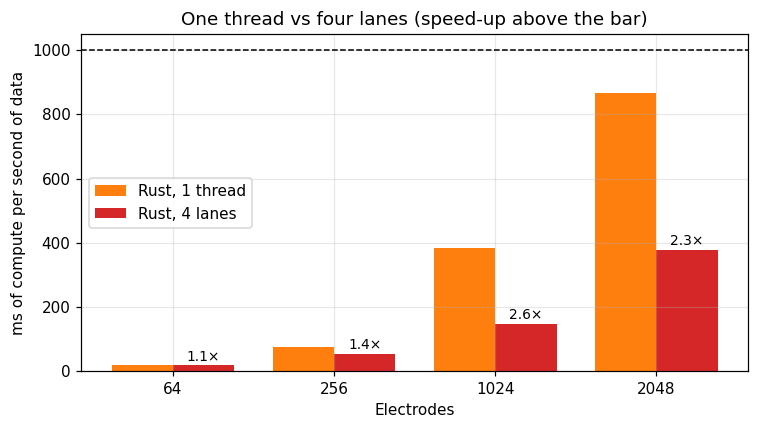

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(CHANNELS)); w = 0.38
one = [STEADY["Rust, 1 thread"][n] for n in CHANNELS]; four = [STEADY["Rust, 4 lanes"][n] for n in CHANNELS]
ax.bar(x - w / 2, one, w, color=COLORS["Rust, 1 thread"], label="Rust, 1 thread")
ax.bar(x + w / 2, four, w, color=COLORS["Rust, 4 lanes"], label="Rust, 4 lanes")
for xi, a, b in zip(x, one, four):
    ax.text(xi + w / 2, b + 15, f"{a / b:.1f}×", ha="center", fontsize=9)
ax.axhline(1000, color="k", ls="--", lw=1)
ax.set_xticks(x); ax.set_xticklabels(CHANNELS); ax.set_xlabel("Electrodes"); ax.set_ylabel("ms of compute per second of data")
ax.set_title("One thread vs four lanes (speed-up above the bar)"); ax.legend(); fig.tight_layout(); plt.show()


## 3. The real recording

The first 10 s of `NSP1_aligned.ns6`, 128 electrodes, LRR parameters. Whole-recording wall time of each path, including the output arrays, divided by the 10 s of data; the lighter bar is Rust's steady-state time from the benchmark. The LRR weights for this file link electrodes across both groups, so Rust uses one lane here regardless of `threads`.

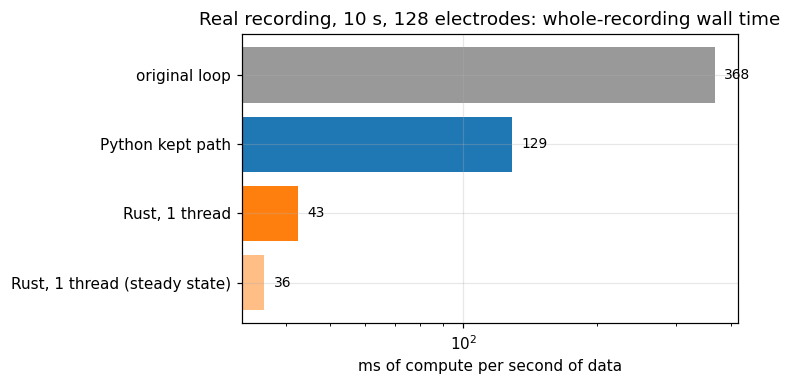

In [6]:
real_times = {
    "original loop": timing.run_original_loop(raw.T.astype(np.float64), reref, thresholds) / SECONDS * 1000,
    "Python kept path": t_py / SECONDS * 1000,
    "Rust, 1 thread": t_rust / SECONDS * 1000,
}
rust_steady_real = timing.rust_bench(["ns6", "--file", RECORDING, "--params", PARAMS, "--seconds", SECONDS, "--threads", "1"])[0]["total_ms_per_s"]

fig, ax = plt.subplots(figsize=(7, 3.6))
names = list(real_times) + ["Rust, 1 thread (steady state)"]
vals = list(real_times.values()) + [rust_steady_real]
bars = ax.barh(names, vals, color=[COLORS[n] for n in real_times] + [COLORS["Rust, 1 thread"]], alpha=1)
bars[-1].set_alpha(0.5)
for b, v in zip(bars, vals):
    ax.text(v * 1.05, b.get_y() + b.get_height() / 2, f"{v:.0f}", va="center", fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("ms of compute per second of data"); ax.invert_yaxis()
ax.set_title(f"Real recording, {SECONDS} s, 128 electrodes: whole-recording wall time"); fig.tight_layout(); plt.show()


## Summary

In [7]:
print("Agreement with the Python kept path (10 s, 128 electrodes, LRR):")
print(f"  spikes {AGREE['spikes_rust']} vs {AGREE['spikes_py']}, bins that differ: {AGREE['spike_mismatch']}")
print(f"  filtered max |difference| {AGREE['filt_max']:.1e} (float32 rounding), spike-band power {AGREE['sbp_max']:.1e} dB")
print()
print("Steady state, ms of compute per second of data (real time = 1000):")
print(f"{'electrodes':>10} {'original':>10} {'Python kept':>12} {'Rust 1t':>9} {'Rust 4 lanes':>13}")
for n in CHANNELS:
    print(f"{n:10d} {STEADY['original loop'][n]:10.0f} {STEADY['Python kept path'][n]:12.0f} {STEADY['Rust, 1 thread'][n]:9.0f} {STEADY['Rust, 4 lanes'][n]:13.0f}")
n = 1024
print()
print(f"Largest stage at {n} electrodes: Python kept path -> {max(SPLIT[('Python kept path', n)], key=SPLIT[('Python kept path', n)].get)}, "
      f"Rust -> {max(SPLIT[('Rust, 1 thread', n)], key=SPLIT[('Rust, 1 thread', n)].get)}")


Agreement with the Python kept path (10 s, 128 electrodes, LRR):
  spikes 26611 vs 26611, bins that differ: 0
  filtered max |difference| 3.8e-06 (float32 rounding), spike-band power 1.1e-05 dB

Steady state, ms of compute per second of data (real time = 1000):
electrodes   original  Python kept   Rust 1t  Rust 4 lanes
        64        204           52        20            18
       256        874          206        76            53
      1024       4620          864       384           148
      2048      14528         1473       868           377

Largest stage at 1024 electrodes: Python kept path -> reverse, Rust -> reverse
